# GA con codificación directa — Maximización de revenue

Exploración del enfoque descrito en `docs/plan_ga_direct_encoding.md`: cada
individuo codifica, para cada servicio, **si se planifica** (`b`) y los
**deltas en minutos** respecto de los horarios solicitados por las RUs
(`δ`). Al decodificar, los deltas se acumulan aguas abajo, de modo que los
tiempos de operación se respetan por construcción; los únicos conflictos se
penalizan en el fitness.

Los datos de entrada son los generados por el cuaderno
`0.0-Synthetic_Data_Generator.ipynb` (`data/synthetic/timetable.yaml` y
`revenue.yaml`): 50 servicios Madrid → Barcelona de un mismo día. Toda la
lógica vive en `craft.ga` (formulación, GA y visualización); este cuaderno
solo compone los helpers sobre la instancia.

## 0. Librerías


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from craft.ga import GA, load_problem
from craft.ga.plotting import (
    plot_evolution,
    plot_genome,
    plot_genome_filmstrip,
    plot_timetable,
    plot_timetable_filmstrip,
    subset_evenly_by_departure,
)

DATA = Path('../data/synthetic')


def hhmm(minutes):
    minutes = int(minutes)
    return f'{minutes // 60:02d}:{minutes % 60:02d}'

## 1. La instancia

`load_problem` construye el problema a partir de los dos archivos del
cuaderno 0.0 (el headway y el margen del IM se leen de sus metadatos). El
genoma tiene un bloque `[b, δ…]` por servicio; el baseline de referencia es
la heurística del paper publicado (resolver los conflictos sobre los
horarios solicitados soltando el servicio de menor canon).

In [2]:
problem = load_problem(DATA / 'timetable.yaml', DATA / 'revenue.yaml')

n_conflicts = int(np.triu(problem.conflict_matrix(problem.requested_schedules), 1).sum())
greedy_n, greedy_revenue = problem.greedy_baseline()
canon_total = sum(p['canon'] for p in problem.revenue_behavior.values())

print(f'servicios solicitados  : {problem.n_services}')
print(f'tamaño del genoma      : {problem.genome_size} genes = '
      f'{problem.n_services} bits b + {problem.genome_size - problem.n_services} deltas')
print(f'safe_headway           : {problem.safe_headway} min | margen del IM: ±{problem.im_mod_margin} min')
print(f'canon total            : {canon_total:.2f}')
print(f'conflictos solicitados : {n_conflicts} pares de servicios')
print(f'baseline greedy        : {greedy_n} servicios, revenue = {greedy_revenue:.2f}')

servicios solicitados  : 50
tamaño del genoma      : 217 genes = 50 bits b + 167 deltas
safe_headway           : 10 min | margen del IM: ±60 min
canon total            : 2028.77
conflictos solicitados : 103 pares de servicios
baseline greedy        : ['00003', '00004', '00009', '00010', '00013', '00015', '00017', '00030', '00032', '00034', '00035', '00036', '00038', '00040', '00044', '00047', '00048'] servicios, revenue = 729.53


## 2. Anatomía de un individuo

El primer gen del bloque es el bit de planificación `b`; el resto son deltas
en minutos sobre las horas de salida solicitadas (`0` = sin cambio). Al
decodificar, el delta de cada estación se **suma a los anteriores** (arrastre),
con el margen del IM en el origen y un tope por parada (`max_stop_time`).

Por ejemplo, con referencias `8:00, 9:00, 10:00` y bloque `[1, 5, 0, 1]`, los
acumulados son `(5, 5, 6)` y el horario decodificado resulta
`8:05, 9:05, 10:06`: el tren no puede llegar antes de lo que ya ha salido.

In [3]:
rng = np.random.default_rng(7)
individual = np.zeros(problem.genome_size, dtype=np.int64)
individual += np.round(rng.normal(0.0, 3.0, individual.shape)).astype(np.int64)
individual[np.array([block.start for block in problem.slices])] = 1
np.clip(individual, problem.lower_bounds, problem.upper_bounds, out=individual)

problem.describe_genome(individual).head(12)

,service,ru,stops,planned,deltas
0,00001,3,3,1,"[1, 0]"
1,00002,3,2,1,[-1]
2,00003,2,7,1,"[0, 4, 0, 0, 1, 1]"
3,00004,3,6,1,"[-3, 0, 2, 0, 0]"
4,00005,1,3,1,"[-4, 0]"
5,00006,2,3,1,"[-4, 1]"
6,00007,1,2,1,[-1]
7,00008,3,6,1,"[-2, 0, 0, 0, 0]"
8,00009,1,6,1,"[-2, 3, 0, 0, 3]"
9,00010,1,7,1,"[0, 0, 0, 0, 0, 4]"


In [4]:
i = next(i for i, sid in enumerate(problem.service_ids)
         if len(problem.reference_schedules[sid]) >= 4)
sid = problem.service_ids[i]
stops = list(problem.requested_schedules[sid])
decoded = problem.decoded_schedule(individual)[sid]
travel_back = problem.schedule_manager.operational_times[sid][-1]

requested_times = [problem.requested_schedules[sid][s][1] for s in stops[:-1]]
requested_times.append(problem.requested_schedules[sid][stops[-1]][0])
decoded_times = [decoded[s][1] for s in stops[:-1]] + [decoded[stops[-1]][0]]

print(f'servicio {sid} | genoma del bloque = {individual[problem.slices[i]].tolist()}')

import pandas as pd

pd.DataFrame({
    'estación': stops,
    'papel': ['origen'] + ['intermedia'] * (len(stops) - 2) + ['destino'],
    'solicitada': [hhmm(t) for t in requested_times],
    'decodificada': [hhmm(t) for t in decoded_times],
    'Δ (min)': [int(d - r) for d, r in zip(decoded_times, requested_times)],
})

servicio 00003 | genoma del bloque = [1, 0, 4, 0, 0, 1, 1]


,estación,papel,solicitada,decodificada,Δ (min)
0,60000,origen,08:05,08:05,0
1,04007,intermedia,08:32,08:36,4
2,70600,intermedia,09:10,09:14,4
3,04040,intermedia,09:37,09:41,4
4,78400,intermedia,10:22,10:27,5
5,04104,intermedia,10:50,10:56,6
6,71801,destino,11:29,11:35,6


Vistas del mismo individuo: el mapa de calor de deltas (azul = adelanto,
rojo = retraso) y el diagrama espacio-tiempo sobre una muestra repartida por
el día — cada servicio mantiene su color entre la línea discontinua
(solicitado) y la continua (decodificado), de modo que el arrastre se ve
directamente.

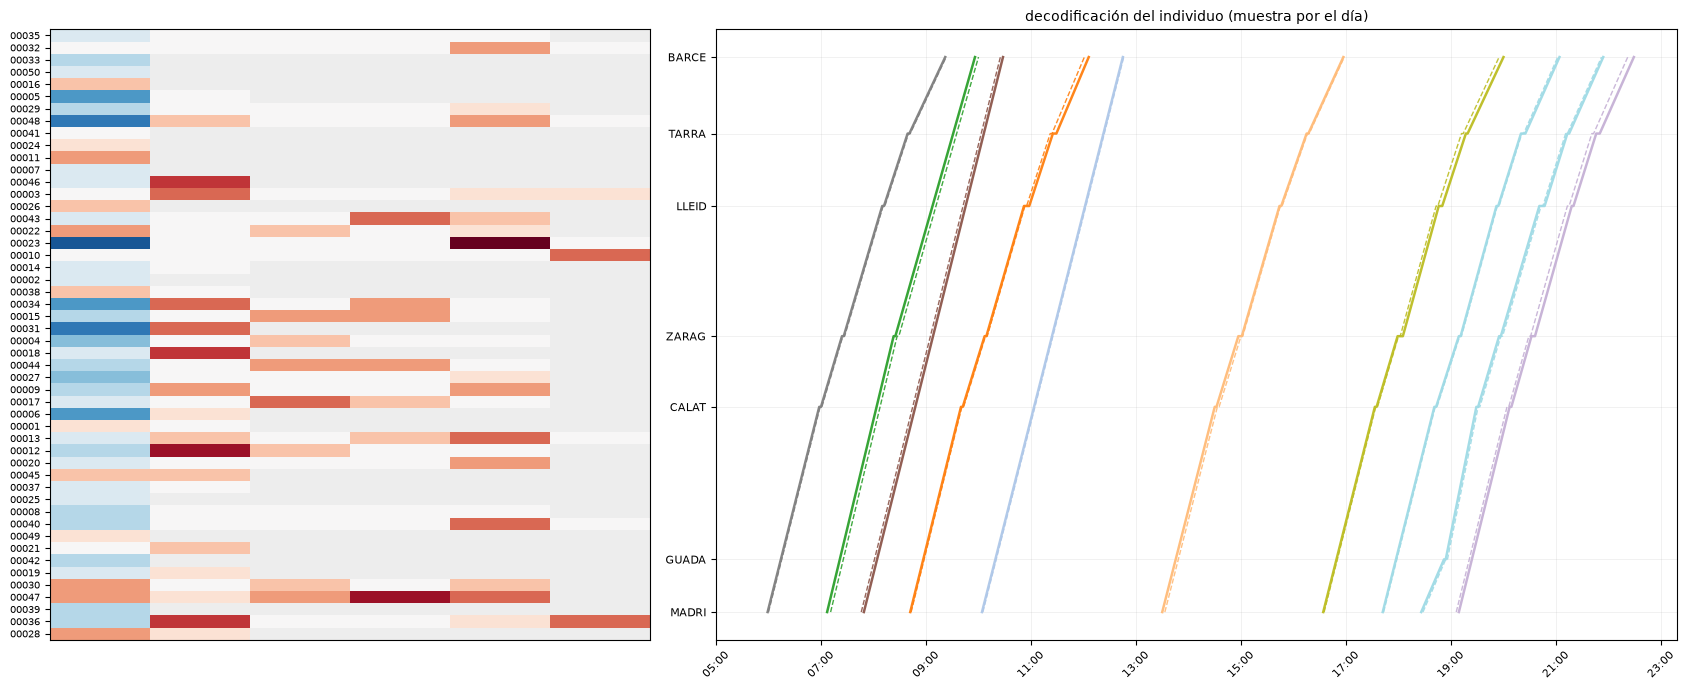

In [5]:
fig, (heat_ax, marey_ax) = plt.subplots(
    1, 2, figsize=(17, 7), gridspec_kw={'width_ratios': [1, 1.6]}
)
plot_genome(problem, individual, ax=heat_ax, show_labels=True)
plot_timetable(
    problem, individual,
    subset=subset_evenly_by_departure(problem, 10),
    ax=marey_ax,
    title='decodificación del individuo (muestra por el día)',
)
fig.tight_layout()
plt.show()

## 3. Optimización

El GA evoluciona la población con selección por torneo, cruce que intercambia
**bloques de servicio completos** (el bit `b` viaja siempre con sus deltas),
mutación entera gaussiana con reinicios a `δ = 0`, y elitismo. El fitness
descuenta de los ingresos una penalización por cada par de servicios
planificados en conflicto, recomputados sobre el horario decodificado.

In [6]:
ga = GA(problem, pop_size=50)
history = ga.optimize(epoch=150, seed=42, verbose=False)

print(f'mejor fitness         : {ga.best_fitness:.2f}')
print(f'servicios planificados: {history["Planned"].iloc[-1]} de {problem.n_services}')
print(f'conflictos finales    : {history["Conflicts"].iloc[-1]}')
print(f'tiempo de ejecución   : {ga.execution_time:.1f} s')

mejor fitness         : 745.29
servicios planificados: 18 de 50
conflictos finales    : 0
tiempo de ejecución   : 6.7 s


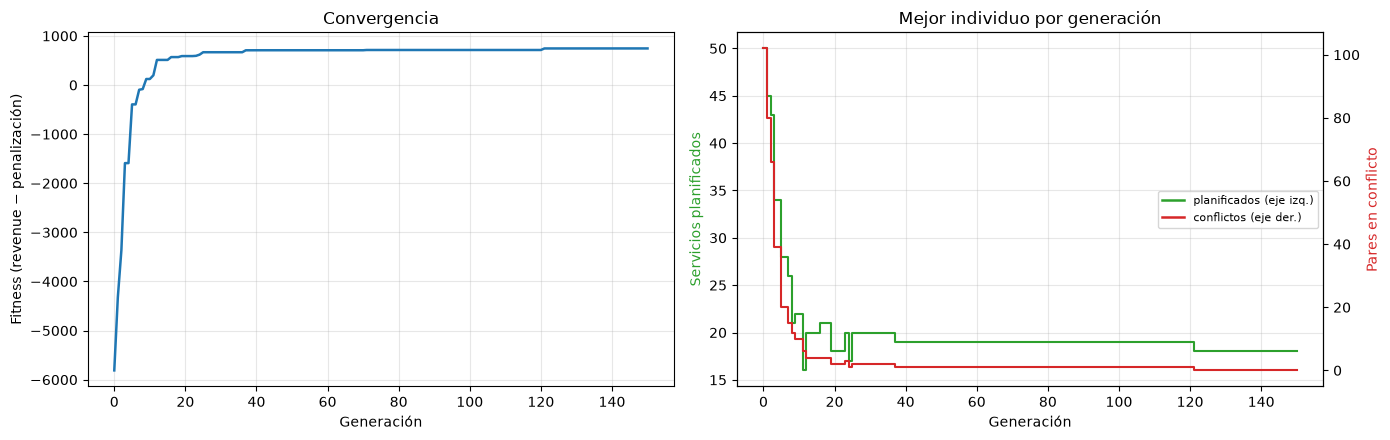

In [7]:
fig = plot_evolution(history)
plt.show()

## 4. Evolución de los individuos

El GA guarda el mejor individuo de cada generación (`best_genomes`): cada
servicio conserva **su color en todos los paneles**, así que se ve qué
servicios se podan (pasan a gris), cuáles se mantienen sin cambio y cuáles
viajan desplazados (línea discontinua del mismo color bajo la continua).

/var/folders/_n/lz98rzln403f9jgxhtvhf_wr0000gn/T/ipykernel_13097/1929190633.py:6: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


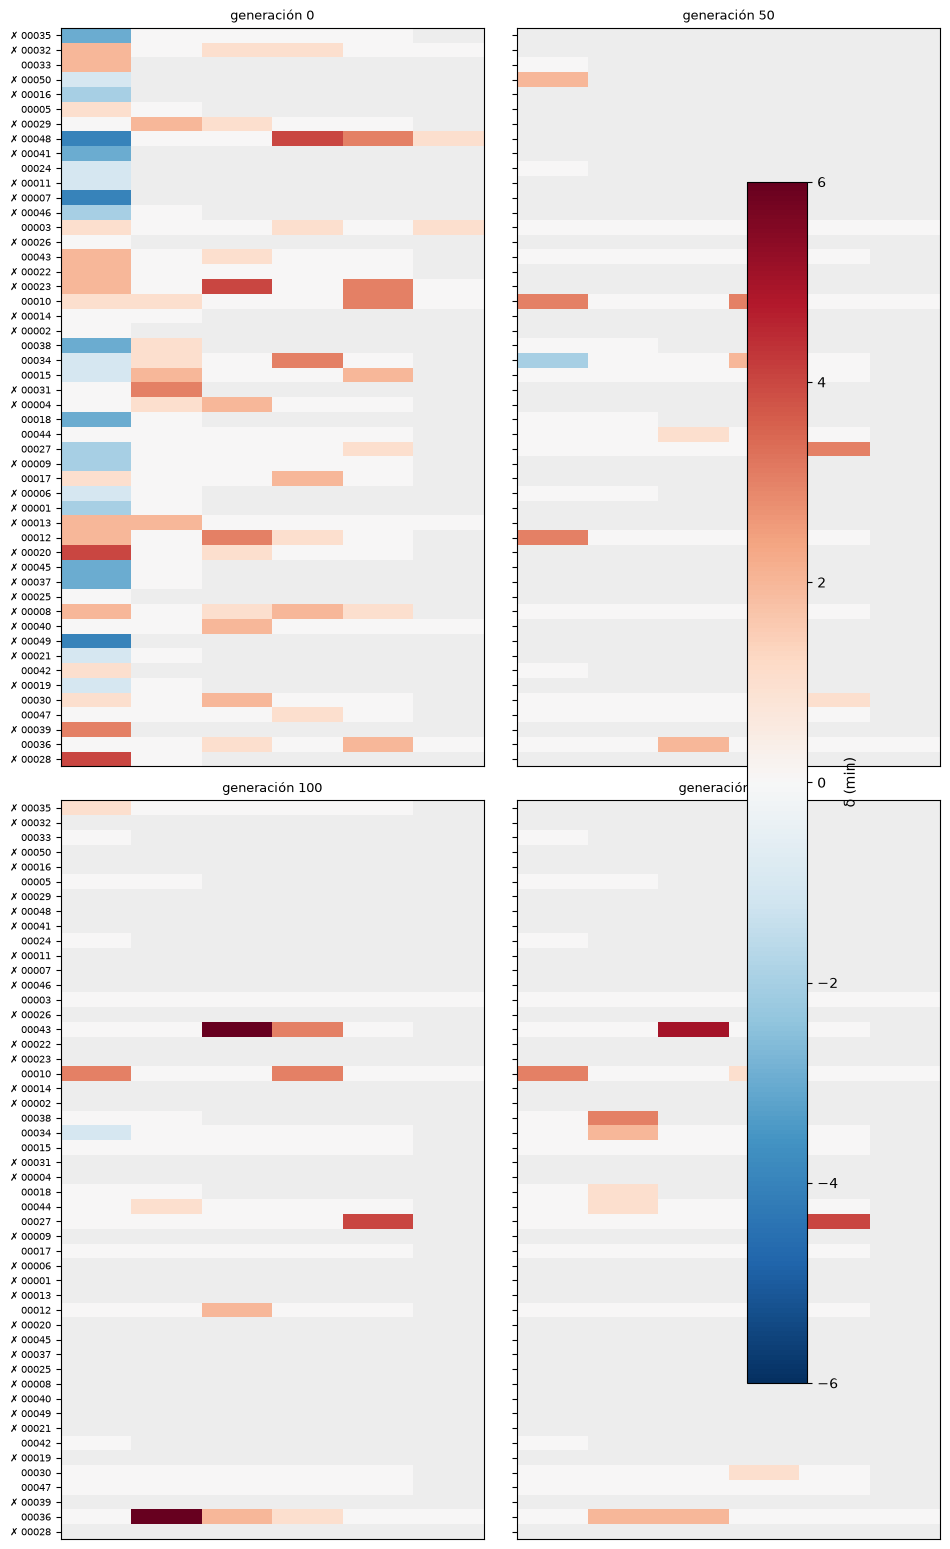

In [8]:
steps = [0, 50, 100, 150]
genomes = ga.best_genomes[steps]
titles = [f'generación {g}' for g in steps]

fig = plot_genome_filmstrip(problem, genomes, titles)
fig.tight_layout()
plt.show()

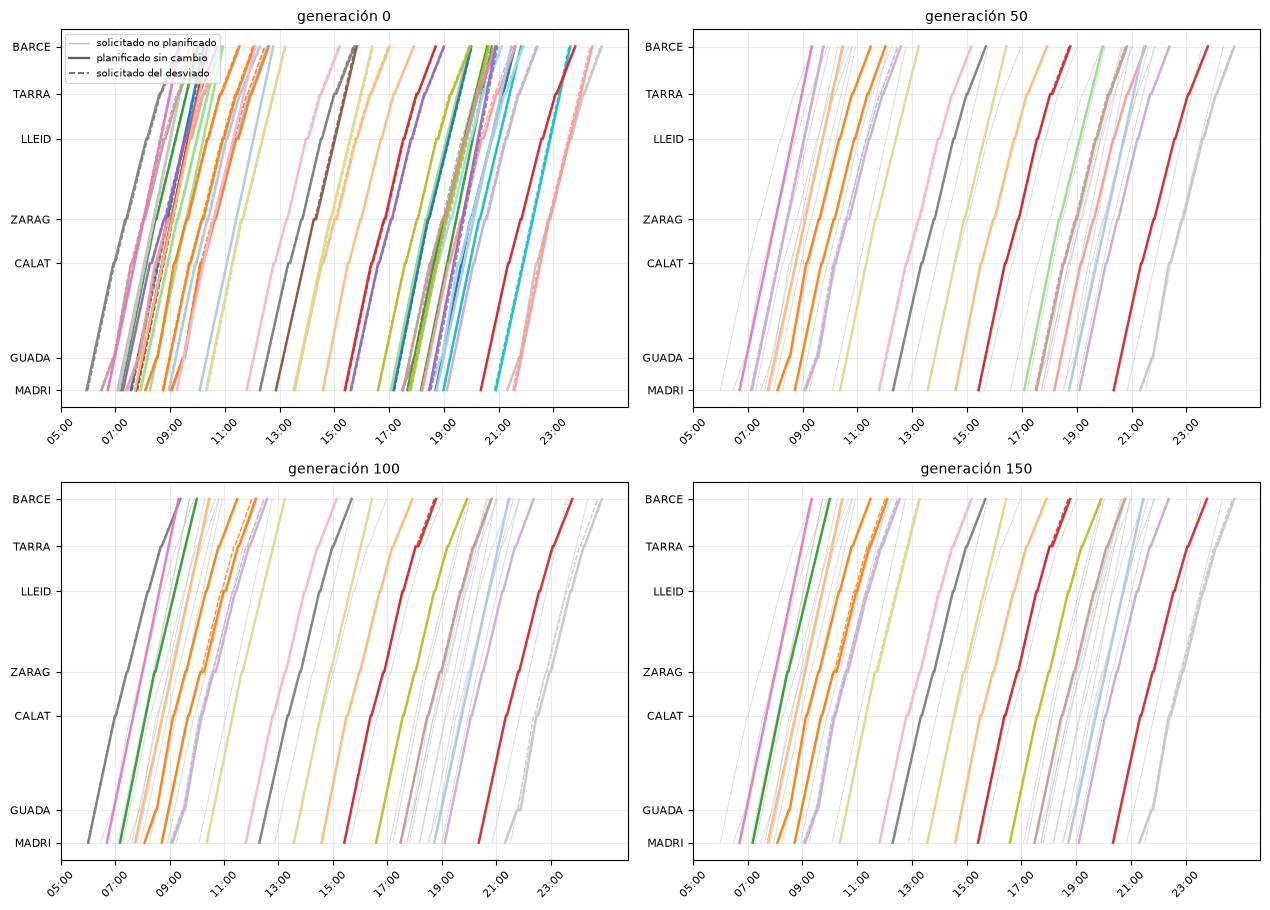

In [9]:
fig = plot_timetable_filmstrip(problem, genomes, titles)
fig.tight_layout()
plt.show()

## 5. El mejor horario

Composición del mejor individuo (qué servicios se planifican, con qué
desviación sobre lo solicitado y qué ingresos aportan) frente al baseline
greedy, y su diagrama espacio-tiempo final.

In [10]:
best_df = problem.schedule_frame(ga.best_solution)
best_df.assign(
    **{
        'salida solicitada': best_df['requested_departure'].map(hhmm),
        'salida final': best_df['final_departure'].map(hhmm),
    }
).drop(columns=['requested_departure', 'final_departure'])

,service,ru,origin_delta,revenue,canon,salida solicitada,salida final
0,00003,2,0,43.520000,43.52,08:05,08:05
1,00005,1,0,39.510000,39.51,07:11,07:11
2,00010,1,3,43.437552,43.53,09:03,09:06
3,00012,1,0,42.820000,42.82,17:29,17:29
4,00015,3,0,42.810000,42.81,12:18,12:18
5,00017,3,0,42.810000,42.81,16:35,16:35
6,00018,1,0,39.507340,39.51,13:34,13:34
7,00024,1,0,37.080000,37.08,07:44,07:44
8,00027,1,0,42.801606,42.82,15:25,15:25
9,00030,1,0,42.817693,42.82,19:06,19:06


In [11]:
residual = problem.conflicting_pairs(ga.best_genome)
total_revenue = best_df['revenue'].sum()
total_canon = best_df['canon'].sum()

print(f'baseline greedy (horarios solicitados): '
      f'{greedy_n} servicios, revenue = {greedy_revenue:.2f}')
print(f'GA (mejor individuo)                  : '
      f'{len(best_df)} servicios, revenue = {total_revenue:.2f}')
print(f'penalización media sobre el canon     : '
      f'{(1 - total_revenue / total_canon) * 100:.1f} %')
print(f'conflictos residuales                 : {len(residual)} {residual}')

baseline greedy (horarios solicitados): ['00003', '00004', '00009', '00010', '00013', '00015', '00017', '00030', '00032', '00034', '00035', '00036', '00038', '00040', '00044', '00047', '00048'] servicios, revenue = 729.53
GA (mejor individuo)                  : 18 servicios, revenue = 745.29
penalización media sobre el canon     : 0.1 %
conflictos residuales                 : 0 []


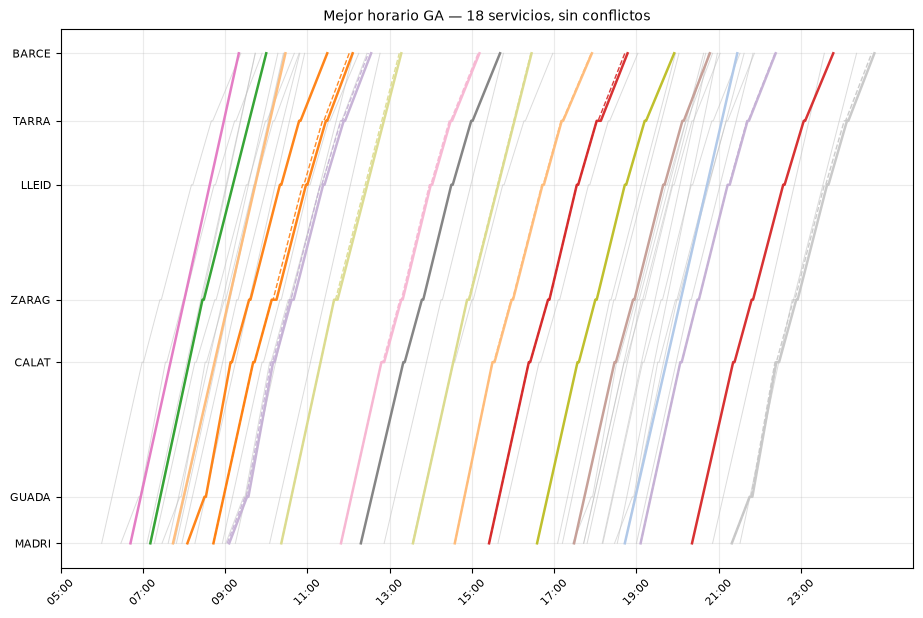

In [12]:
ax = plot_timetable(
    problem, ga.best_genome,
    title=f'Mejor horario GA — {len(best_df)} servicios, sin conflictos',
)
plt.show()

## Notas

**Qué revisar en este cuaderno**

- El formato del individuo (bloques `[b, δ…]`), su decodificación con arrastre
  aguas abajo y sus dos vistas (mapa de calor y espacio-tiempo), sección 2.
- La evolución del GA: convergencia, planificados y conflictos, sección 3.
- La **evolución de los individuos** en filmstrips con color por servicio
  consistente entre paneles, sección 4.
- La calidad del mejor horario frente al baseline greedy, sección 5.

**Integración con otros solvers**: el contrato `craft.ga.base.Problem`
(genoma + `fitness`/`decode`) es el único punto de enganche; el GA de este
repo y cualquier metaheurístico externo (p. ej. un GA custom) consumen el
mismo problema.

**Siguiente fase** (según `docs/plan_ga_direct_encoding.md`): experimentos
comparativos con los backends actuales y ajuste de hiperparámetros (fase 4).
Los mismos artefactos pueden generarse por CLI con
`python scripts/run_ga.py`, que guarda convergencia, mejor horario y
filmstrips en `data/results/`.